# Forecasting after an unfinished season

**Level:** 2. **Prerequisites:** Earlier lessons in this topic; NumPy arrays and temporal evaluation. **Reading time:** 40 minutes.

**Question:** When the forecast origin moves five observations earlier, does HoltWinters continue the correct seasonal phase, and how do its lead-specific errors compare with a repeated season?

## Objectives

Investigate a concrete implementation risk rather than assuming that a familiar method name guarantees a correct forecast. We will shorten a committed history, construct the corresponding target from observations that follow the new origin, and call the actual additive HoltWinters implementation. We then compare the path with two simpler methods and inspect both aggregate and lead-specific errors. The experiment deliberately changes the temporal cut while keeping the underlying observed sequence fixed.

A seasonal model stores components indexed by position in a cycle. If a history ends halfway through that cycle, forecasting must continue from that position. Restarting the seasonal component at its first slot can generate a plausible looking oscillation with the wrong phase. This defect is particularly easy to miss when every demonstration history happens to contain an integer number of seasons. The example therefore removes a fixed, predeclared number of observations before fitting.

## Setup

Use the isolated notebook environment with these direct pins. The code imports the product functions instead of defining another HoltWinters implementation whose behaviour might differ from the app.

```text
pip install numpy==2.4.6
pip install scipy==1.15.3
pip install matplotlib==3.10.8
pip install statsforecast==2.0.3
pip install lightgbm==4.6.0
pip install mlforecast==1.0.31
pip install nbformat==5.11.1
pip install nbclient==0.11.0
pip install ipykernel==7.4.0
pip install stumpy==1.14.1
pip install antropy==0.2.2
pip install nolds==0.6.3
pip install pycatch22==0.4.5
pip install scikit-learn==1.9.1
pip install preqts==0.3.0
pip install forecastscope==0.1.4
```


In [1]:
# Configure a portable lesson session; no data are downloaded.
from pathlib import Path
import sys
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
root = next(p for p in Path.cwd().parents if (p / "VERSION").is_file() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from engine.model.forecasters import seasonal_naive, ses, holt, holt_winters, theta
from engine.model.forecasters import gaussian_quantiles
from engine.model.context_memory import fit_context_memory
from engine.reevaluation import metrics
from engine.engines.statsforecast_engine import StatsforecastForecaster
from engine.engines.lightgbm_engine import LightGBMForecaster
plt.rcParams.update({"figure.figsize": (8, 3), "figure.dpi": 95, "font.size": 10})
plt.rcParams["svg.hashsalt"] = "chronoscope-lessons"
import importlib.metadata
packages = ("numpy", "scipy", "matplotlib", "statsforecast", "lightgbm", "mlforecast",
            "nbformat", "nbclient", "ipykernel")
for package in packages:
    print(package, importlib.metadata.version(package))

# Load the observed source once; later cells contain only scientific operations.
electricity_values = np.loadtxt(root / "data/examples/electricity_sample.csv",
                                delimiter=",", skiprows=1, usecols=2)

print("ForecastScope", importlib.metadata.version("forecastscope"))


numpy 2.4.6
scipy 1.15.3
matplotlib 3.10.8
statsforecast 2.0.3
lightgbm 4.6.0
mlforecast 1.0.31
nbformat 5.11.1
nbclient 0.11.0
ipykernel 7.4.0
ForecastScope 0.1.4


## Data

The initial phase illustration reads the synthetic TRND_seasonal fixture from `data/derived/TRND_seasonal/trace.json`; it is generated by the product's `data-pipeline/engine/cases/forecast_cases.py` with seed 42 and period 12, under the MIT licence. Its history and final actual fields are contiguous source values in generated units. The subsequent phase sensitivity uses authentic client MT_010 from UCI ElectricityLoadDiagrams20112014 (https://doi.org/10.24432/C58C86, CC BY 4.0), `data/examples/electricity_sample.csv`. Its hourly labels group four 15-minute kW readings by summation; no conversion to energy is made.


In [2]:
# The committed trace separates available history from the unseen final block.
trace = json.loads((root / "data/derived/TRND_seasonal/trace.json").read_text())
history = np.array(trace["history"], dtype=float)
actual = np.array(trace["actual"], dtype=float)
m, h = trace["seasonality"], trace["horizon"]
comparison = json.loads((root / "data/derived/reevaluation.json").read_text())
print("History:", len(history), "Season:", m, "Holdout:", h)


History: 168 Season: 12 Holdout: 12


## Method

The first fit uses the shortened prefix. The second fit uses the complete original history and is retained only to distinguish the two forecast origins. In additive HoltWinters, level, trend and seasonal components are updated together using finite parameter grids. The forecast must use the seasonal slot corresponding to the full length of the fitting prefix plus the requested lead. The printed remainder identifies whether the shortened history ends on a cycle boundary. That value is a direct check of the experimental condition, rather than a forecast accuracy measure.


In [3]:
# Remove five known observations to create an incomplete terminal season.
short = history[:-5]
short_actual = np.concatenate((history[-5:], actual))[:h]
hw_point, hw_sigma = holt_winters(short, m, h)
full_hw, full_sigma = holt_winters(history, m, h)
print("Removed observations:", len(history) - len(short))
print("Partial history remainder:", len(short) % m)
print("Forecast horizon:", h)


Removed observations: 5
Partial history remainder: 7
Forecast horizon: 12


SeasonalNaive provides a phase-aware reference because it copies the final observed cycle relative to the new origin. Theta supplies a second comparison with drift but without the same automatically fitted seasonal structure. Both must be refitted on the shortened history. Keeping a forecast trained on the original longer history would give that competitor access to observations that the earlier-origin method could not have seen. This is a small example of temporal leakage that a shared target alone would not prevent.


In [4]:
# Refit the seasonal reference and Theta at the earlier origin as well.
short_naive, short_sigma = seasonal_naive(short, m, h)
short_theta, short_theta_sigma = theta(short, m, h)
short_q = gaussian_quantiles(hw_point, hw_sigma, (0.1, 0.5, 0.9))
print("HoltWinters first prediction:", round(float(hw_point[0]), 4))


HoltWinters first prediction: 109.587


The corrected local Theta equation remains useful as a contrasting mechanism even when its score is not the main outcome. Its finite-history correction depends on the number of observations available at fitting, so moving the origin also changes that correction. A test that compares only forecast shapes can overlook such dependencies. We call the implementation again with the original prefix to make its information set explicit, while leaving the earlier-origin scores tied exclusively to earlier-origin predictions.


In [5]:
# Fit the finite-history Theta implementation on the same prefix.
theta_point, theta_sigma = theta(history, m, h)
theta_q = gaussian_quantiles(theta_point, theta_sigma, (0.1, 0.5, 0.9))
print("Theta first prediction:", round(float(theta_point[0]), 4))


Theta first prediction: 113.1748


Scoring uses the shortened prefix to compute the historical seasonal scale and the newly assembled target block to compute future errors. Coverage is the fraction of those targets falling between the lower and upper Gaussian quantiles. It is a sample fraction from one block, not a probability guarantee for the next individual observation. Width and coverage should be considered together: a method can cover more targets by producing intervals too wide to guide a useful action. This lesson prints coverage but does not optimize interval settings against the reserved target.


In [6]:
# The earlier-origin target is different, so its scores form a separate experiment.
short_score = metrics(short, short_actual, hw_point, short_q[:, 0], short_q[:, 2], m)
print("Earlier-origin MASE:", round(short_score["mase"], 4))
print("Earlier-origin coverage:", round(short_score["coverage"], 4))


Earlier-origin MASE: 0.4948
Earlier-origin coverage: 1.0


In the first figure, compare the timing of the predicted peaks with the corresponding observed peaks. A correct implementation can still make large errors because its trend or estimated seasonal amplitude is imperfect. Conversely, a low aggregate error on a nearly flat series would be weak evidence that seasonal indexing was correct. This generated case has visible structure specifically so that phase can be inspected. The independent regression tests in the repository additionally exercise histories whose lengths are not divisible by the seasonal period.


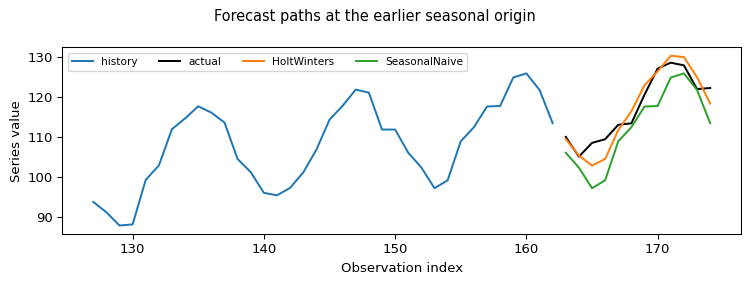

In [7]:
# Display phase alignment around the deliberately shifted origin.
fig, ax = plt.subplots()
x = np.arange(len(short), len(short) + h)
ax.plot(np.arange(len(short))[-36:], short[-36:], label="history")
ax.plot(x, short_actual, color="black", label="actual")
ax.plot(x, hw_point, label="HoltWinters")
ax.plot(x, short_naive, label="SeasonalNaive")
ax.set(xlabel="Observation index", ylabel="Series value")
ax.legend(ncol=4, fontsize=8)
fig.suptitle('Forecast paths at the earlier seasonal origin', fontsize=11)
fig.tight_layout()
plt.show()


The displayed paths distinguish alignment from accuracy. Following the correct slots is necessary for the stated HoltWinters algorithm, but it does not ensure that the resulting seasonal estimate is appropriate for a future regime. Check the origin and the oscillation together rather than attributing every discrepancy to phase. A changed level or imperfect drift can shift the whole forecast while leaving its seasonal positions intact. That interpretation motivates looking at individual leads in the next figure.

Lead-specific absolute errors preserve the units of the series and expose which future observations dominate the average. Each point is one error at one lead, not an estimate averaged over many origins. A peak in this curve can therefore reflect one unusual target rather than a general weakness at that horizon. We show the seasonal reference on the same axes so that any relative improvement is visible directly. No confidence interval or significance test is attached to this small deterministic comparison.


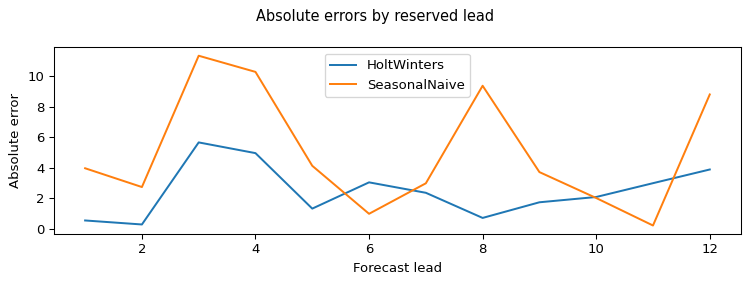

Seasonal reference MASE: 1.0136


In [8]:
# Inspect errors by lead; an average can hide phase-specific failures.
short_naive_q = gaussian_quantiles(short_naive, short_sigma, (0.1, 0.5, 0.9))
short_naive_score = metrics(short, short_actual, short_naive, short_naive_q[:, 0], short_naive_q[:, 2], m)
fig, ax = plt.subplots()
ax.plot(np.arange(1, h + 1), np.abs(short_actual - hw_point), label="HoltWinters")
ax.plot(np.arange(1, h + 1), np.abs(short_actual - short_naive), label="SeasonalNaive")
ax.set(xlabel="Forecast lead", ylabel="Absolute error")
ax.legend()
fig.suptitle('Absolute errors by reserved lead', fontsize=11)
fig.tight_layout()
plt.show()
print("Seasonal reference MASE:", round(short_naive_score["mase"], 4))


The error plot reveals whether the two methods fail on the same positions or trade errors across the block. Their curves can cross, so a lower average does not imply improvement at every lead. That matters when a planning process values near-term service more than a distant forecast. Such costs would need to be declared before choosing a weighted criterion. The present lesson keeps every lead equally weighted and retains the seasonal reference's independently printed MASE.



Implementation correctness and empirical quality are separate conclusions. The independent partial-season test can falsify the indexing rule without claiming population superiority. The observed error can falsify an accuracy expectation on this case without proving the indexing rule wrong. Keep both forms of evidence when diagnosing a forecast, and retain an unfavorable result instead of changing the origin until a preferred method wins.

### Sensitivity to the position inside a day

Number the prefix observations from zero. If its length is $n$, the next
seasonal slot is $n\bmod m$. An additive HoltWinters fit retains a level
$\ell$ and trend $b$ in source units and source units per step, plus $m$
seasonal offsets $s$ in source units. For a lead $j$ counted from one, the
released forecast is

$$
\widehat y_{n+j-1} = \ell + jb + s_{(n+j-1)\bmod m}.
$$

For $m=12$, a prefix of length 125 advances to slot 5. Starting the forecast
at slot zero would reuse the seasonal position of the first observation,
although the predicted day has already advanced five slots. Refit before
changing the cutoff, because moving it also changes the estimated level and
trend. The search in this implementation tries four level coefficients,
two trend coefficients and three seasonal coefficients. It minimizes squared
one-step residuals after the initial seasonal cycle. Below two complete
cycles, the public method falls back to Holt, since it cannot estimate this
seasonal initialization from the available observations.

The synthetic control above isolates phase with a known period. The following
experiment moves to the committed MT_010 electricity excerpt (Trindade,
UCI, CC BY 4.0, [DOI 10.24432/C58C86](https://doi.org/10.24432/C58C86)).
Each hourly-labelled value sums four successive quarter-hour power readings
in kW. These sums have not been converted to energy. The first retained
timestamp is 00:15 and later timestamps advance by one hour. The data contain
480 rows. A daily reference has $m=24$ and a weekly reference $m=168$. We
compare both seasonal-naive forecasts and daily HoltWinters at cutoffs
312 through 368, stepping by seven observations to move across different
daily phases. At each cutoff all three forecast the same 24 reserved
observations. We score them with one common daily lag scale so that the
weekly method does not get a different denominator.

$$
s_{24}(y_{0:n})=\frac{1}{n-24}\sum_{i=24}^{n-1}|y_i-y_{i-24}|,
\qquad
\operatorname{MASE}_{24}=\frac{\sum_{j=1}^{24}|a_j-\widehat y_{n+j-1}|}{24s_{24}(y_{0:n})}.
$$

The daily seasonal reference must copy the 24 values immediately preceding
the cutoff. The cell calculates the maximum difference from direct indexing, which should be zero.


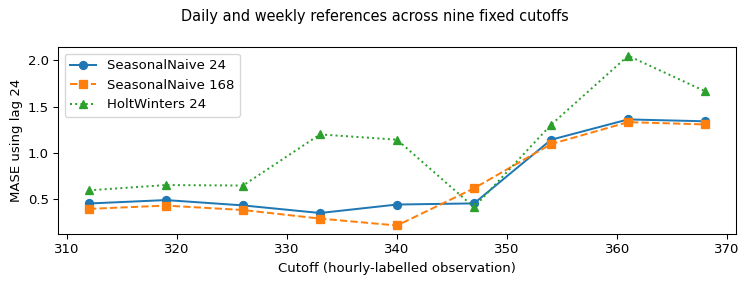

Largest difference from direct seasonal indexing: 0.0
Cutoff  /  next daily phase  /  daily MASE  /  weekly MASE  /  smoothed MASE
   312         0     0.4543     0.3963     0.5965
   319         7     0.4912     0.4319     0.6531
   326        14     0.4338     0.3839     0.6479
   333        21     0.3518     0.2916     1.1994
   340         4     0.4431     0.2171     1.1424
   347        11     0.4554     0.6186     0.4142
   354        18     1.1421     1.0952     1.3039
   361         1     1.3610     1.3317     2.0477
   368         8     1.3407     1.3069     1.6645


In [9]:
# Compare daily phase and a weekly seasonal reference on the same reserved hours.
electricity = electricity_values
origins = np.arange(312, 369, 7)
scores, reference_errors = [], []
for origin in origins:
    prefix = electricity[:origin]
    targets = electricity[origin:origin + 24]
    daily, _ = seasonal_naive(prefix, 24, 24)
    weekly, _ = seasonal_naive(prefix, 168, 24)
    smooth, _ = holt_winters(prefix, 24, 24)
    reference_errors.append(np.max(np.abs(daily - prefix[origin - 24:origin])))
    scale = np.mean(np.abs(prefix[24:] - prefix[:-24]))
    scores.append([np.mean(np.abs(targets - path)) / scale for path in (daily, weekly, smooth)])
scores = np.asarray(scores)
fig, ax = plt.subplots()
for j, (name, style) in enumerate((("SeasonalNaive 24", "o-"), ("SeasonalNaive 168", "s--"), ("HoltWinters 24", "^:"))):
    ax.plot(origins, scores[:, j], style, label=name)
ax.set(xlabel="Cutoff (hourly-labelled observation)", ylabel="MASE using lag 24")
ax.legend()
fig.suptitle('Daily and weekly references across nine fixed cutoffs', fontsize=11)
fig.tight_layout()
plt.show()
print("Largest difference from direct seasonal indexing:", max(reference_errors))
print("Cutoff  /  next daily phase  /  daily MASE  /  weekly MASE  /  smoothed MASE")
for origin, row in zip(origins, scores, strict=True):
    print(f"{origin:6d} {origin % 24:9d} " + " ".join(f"{value:10.4f}" for value in row))


The plot gives a conditional comparison at each cutoff. A curve crossing
changes the local ordering. Read the printed phase beside the observation
index: the same phase can recur after a different calendar history, so the
phase by itself does not explain every score difference. The target windows
overlap because seven observations separate cutoffs and each block has
24 observations. The nine points therefore do not constitute nine
independent replications. Also, the weekly reference accesses a specific
earlier weekday rather than fitting a weekly effect. A poor weekly score at
one cutoff does not disprove weekly structure.

### Using this method on your own data

Supply one timestamp-sorted, equally spaced finite series and identify which
values were available at the forecast origin. For hourly observations, try
period 24 when a daily cycle is scientifically relevant. Confirm the sampling
cadence before comparing period 168. Distinguish a missing hour from an
observed zero, and do not quietly compress the timestamp index when there are
gaps. Split off the next contiguous block before calling
`holt_winters(prefix, m, horizon)`. The method returns the forecast vector
and a residual dispersion in the input's measurement unit. Check that the
vector has the requested length and compare its phase with the independently
indexed seasonal reference. Calculate the common scale only from the prefix.
A constant or exactly periodic prefix can have zero lagged error and thus
an unavailable scaled score. Keep absolute errors in that case. When the
residual dispersion is used to form a Gaussian interval, assess its observed
coverage and width separately from point error. A forecast may have a correct
phase and still miss a shift in level or amplitude.


## Results

**Answer:** Earlier-origin HoltWinters has MASE 0.4948, versus 1.0136 for SeasonalNaive. Removing five observations creates an unfinished season that the corrected implementation continues from its actual terminal position. The paths and printed earlier-origin scores quantify this case. The error curve compares every future lead with SeasonalNaive on the same new target block; it does not justify ranking the methods against scores from the original, later origin.

## Summary

Record the exact information set whenever the temporal cut moves. Build the corresponding future target in chronological order, refit all competitors, and recalculate the historical scale from that prefix. Use adversarial histories with incomplete seasons to test a seasonal algorithm. Then examine both whole-block scores and individual errors, while keeping clear that one forecast origin supplies neither a population estimate nor a deployment acceptance test.

## References

- Seasonal continuation: https://otexts.com/fpp3/holt-winters.html
- Theta correction: https://robjhyndman.com/papers/Theta.pdf
- Error scaling: https://doi.org/10.1016/j.ijforecast.2006.03.001
- Feature-dependent combinations: https://doi.org/10.1016/j.ijforecast.2019.02.011
- Dynamic ensembles: https://doi.org/10.1007/s10994-018-05774-y
- A. Trindade, ElectricityLoadDiagrams20112014, UCI. [Dataset](https://doi.org/10.24432/C58C86).
